# Experiment 30: Generative Model Output Comparison and Evaluation

Management must choose a generative model based on image quality and variety. We sample 1,000 outputs from the VAE and GAN from Experiment 29, train a Fashion-MNIST classifier as a feature extractor, estimate classifier-based Inception Score and FID, inspect class diversity and compare feature distributions.

**Tools:** TensorFlow, Keras, NumPy, Pandas, Scikit-learn, Matplotlib, SciPy.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Generate 1,000 samples from each model.  2. Compute classifier-based Inception Score and FID.  3. Measure class diversity and check for mode collapse.  4. Plot real/generated feature distributions with PCA.  5. Tabulate metrics and give a metric-based recommendation.

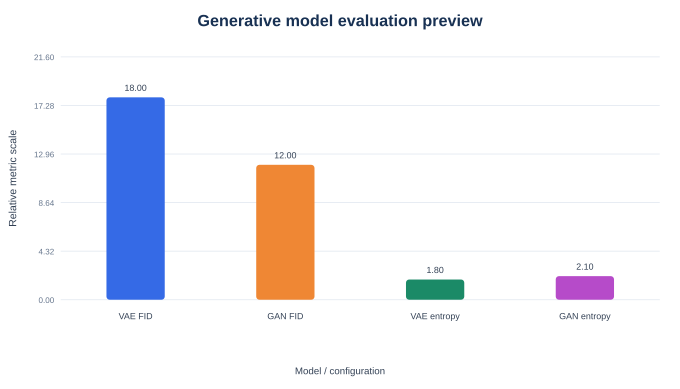

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.decomposition import PCA
from scipy.linalg import sqrtm

# If this notebook is opened separately, first run Experiment 29 and keep its saved models nearby.
from pathlib import Path
if "decoder" not in globals():
    decoder=tf.keras.models.load_model("Exp29_vae_decoder.keras")
if "generator" not in globals():
    generator=tf.keras.models.load_model("Exp29_gan_generator.keras")
if "fashion_eval" not in globals():
    (_, _),(x_test_eval,y_test_eval)=tf.keras.datasets.fashion_mnist.load_data()
    fashion_eval=x_test_eval[:2000].astype("float32")/127.5-1.
    fashion_labels=y_test_eval[:2000]

# 1,000 outputs from the VAE and GAN built in Experiment 29.
z_vae=tf.random.normal((1000,2))
generated_vae=decoder.predict(z_vae,verbose=0)
generated_gan=generator(tf.random.normal((1000,64)),training=False).numpy()
real=(fashion_eval[:1000]+1)/2
generated_vae=(generated_vae+1)/2
generated_gan=(generated_gan+1)/2

# Train a compact classifier on a subset of Fashion-MNIST; use its hidden layer as features.
(xc,yc),_=tf.keras.datasets.fashion_mnist.load_data()
xc=xc[:12000].astype("float32")/255.
classifier=tf.keras.Sequential([
    tf.keras.layers.Input((28,28,1)),tf.keras.layers.Conv2D(16,3,activation="relu"),
    tf.keras.layers.MaxPooling2D(),tf.keras.layers.Conv2D(32,3,activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),tf.keras.layers.Dense(32,activation="relu",name="features"),
    tf.keras.layers.Dense(10,activation="softmax")])
classifier.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
classifier.fit(xc[...,None],yc[:len(xc)],epochs=4,batch_size=128,validation_split=.1,verbose=0)
feature_model=tf.keras.Model(classifier.input,classifier.get_layer("features").output)

def outputs_and_features(images):
    if images.ndim==3: images=images[...,None]
    probs=classifier.predict(images,verbose=0)
    feats=feature_model.predict(images,verbose=0)
    return probs,feats
real_prob,real_feat=outputs_and_features(real)
vae_prob,vae_feat=outputs_and_features(generated_vae)
gan_prob,gan_feat=outputs_and_features(generated_gan)

def inception_score(probs):
    marginal=probs.mean(axis=0)
    kl=np.sum(probs*(np.log(probs+1e-8)-np.log(marginal+1e-8)),axis=1)
    return float(np.exp(kl.mean()))
def fid(a,b):
    ma,mb=a.mean(0),b.mean(0)
    ca=np.cov(a,rowvar=False);cb=np.cov(b,rowvar=False)
    root=sqrtm(ca@cb)
    if np.iscomplexobj(root):root=root.real
    return float(np.sum((ma-mb)**2)+np.trace(ca+cb-2*root))
def entropy_of_classes(probs):
    p=probs.mean(0)
    return float(-np.sum(p*np.log(p+1e-8)))
metrics=[]
for name,probs,feats in [("VAE",vae_prob,vae_feat),("GAN",gan_prob,gan_feat)]:
    class_counts=np.bincount(probs.argmax(1),minlength=10)
    metrics.append({"model":name,"classifier Inception Score":inception_score(probs),
                    "FID (classifier features)":fid(real_feat,feats),
                    "class entropy (nats)":entropy_of_classes(probs),
                    "generated classes":int(np.count_nonzero(class_counts)),
                    "dominant class fraction":class_counts.max()/class_counts.sum()})
    print(name,"predicted class counts:",class_counts)
table=pd.DataFrame(metrics)
print("\n",table.round(3).to_string(index=False))

# PCA view of classifier features: real and both generated sets.
combined=np.vstack([real_feat,vae_feat,gan_feat])
coords=PCA(n_components=2).fit_transform(combined)
n=len(real_feat)
plt.figure(figsize=(7,5))
plt.scatter(coords[:n,0],coords[:n,1],s=8,alpha=.3,label="real")
plt.scatter(coords[n:2*n:4,0],coords[n:2*n:4,1],s=10,alpha=.5,label="VAE")
plt.scatter(coords[2*n::4,0],coords[2*n::4,1],s=10,alpha=.5,label="GAN")
plt.title("Classifier-feature PCA: real and generated images")
plt.xlabel("PC1");plt.ylabel("PC2");plt.legend();plt.tight_layout();plt.show()

best=table.sort_values(["FID (classifier features)","class entropy (nats)"],
                       ascending=[True,False]).iloc[0]["model"]
print(f"Recommendation by lower FID, then higher class entropy: {best}. "
      "Use the table and image grids together; these classifier-based scores are estimates, not a universal quality measure.")